# 07 — How good is the forecast? Error by horizon, model comparison and errors of each kind

Notebook 05d showed that the arrival + detection model beats a model of records only in two backtests. This notebook asks four follow-up questions:

1. **How does the error grow with the forecast horizon?** Trained up to 2015, the model is scored on each year from 2016 (1 year ahead) to 2025 (10 years ahead).
2. **Is the improvement real or noise?** A paired bootstrap over 250-km spatial blocks gives a confidence interval for the difference in log loss between two models scored on the same cells.
3. **Does the desert limit help?** The same comparison, with and without the limit (desert cells cannot be colonised).
4. **What kinds of mistakes does it make?** False positives and false negatives when the probabilities are turned into yes/no at 50%.

**Scores.** The **log loss** is the average of −log(probability the model gave to what actually happened). A cell that got a record and had been given 0.9 costs −log(0.9) = 0.11; one given 0.01 costs −log(0.01) = 4.6. It rewards confident correct forecasts and heavily punishes confident mistakes; lower is better. The **Brier score** is the mean squared difference between probability and outcome (0 or 1). Both are proper scoring rules (Gneiting & Raftery 2007): a model gets its best expected score only by reporting its true beliefs. Scores are computed over the cells without records at the cut-off; the outcome is whether a cell has a toad record by each year.

The definitions (data, detection and arrival models, bootstrap, simulation) are the same as in notebook 05d.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from scipy.special import expit, log_expit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))
from colonization import FEATURES, cell_year_table, simulate
from environment import BIOCLIM_VARIABLES, environmental_grid
from front import records_to_cells
from occupancy import ArrivalLikelihood, counts_per_cell_year, fit_detection, simulate_presence, value_at

PROCESSED, RAW = PROJECT_ROOT / "data" / "processed", PROJECT_ROOT / "data" / "raw"
FIGURES = PROJECT_ROOT / "figures"
CELL_SIZE_M = 25_000
CELL_KM2 = (CELL_SIZE_M / 1000) ** 2
CLIMATE = list(BIOCLIM_VARIABLES.values())
TRAIN_START = 1990
N_BOOTSTRAP = 30
BLOCK_CELLS = 10  # 10 x 25 km = 250 km blocks

cells = environmental_grid(CELL_SIZE_M)
toads = pd.read_csv(PROCESSED / "rhinella_marina_clean.csv")
cells = cells.merge(records_to_cells(toads, CELL_SIZE_M)[["cx", "cy", "first_year"]], how="left", on=["cx", "cy"])
cells["first_year"] = cells["first_year"].fillna(np.inf)
cells["x_km"] = (cells["cx"] + 0.5) * CELL_SIZE_M / 1000
cells["y_km"] = (cells["cy"] + 0.5) * CELL_SIZE_M / 1000
first_year = cells["first_year"].to_numpy()
x_km = cells["x_km"].to_numpy()
west = (cells["lon"] < 141).to_numpy()
outside = (cells["lon"] < 138).astype(int).to_numpy()
desert = (cells["climate_zone"] == "Desert (BW)").to_numpy()
pilbara = (cells["lon"].between(116, 121) & cells["lat"].between(-23, -19)).to_numpy()

amphibians = pd.read_csv(RAW / "amphibia_ala.csv", low_memory=False)
others = amphibians.loc[
    (amphibians["scientificName"] != "Rhinella marina")
    & amphibians["decimalLatitude"].notna() & amphibians["year"].notna()
    & ~(amphibians["coordinateUncertaintyInMeters"] > 10_000)
]
effort = counts_per_cell_year(others, cells, CELL_SIZE_M)
toad_counts = counts_per_cell_year(toads.dropna(subset=["year"]), cells, CELL_SIZE_M)
print(f"{len(cells):,} cells; effort records {int(effort.to_numpy().sum()):,}; toad records {int(toad_counts.to_numpy().sum()):,}")

12,312 cells; effort records 1,843,125; toad records 34,607


In [2]:
REGION = ["outside_queensland", "outside_x_log_distance", "outside_x_neighbours_50km"]
ARRIVAL = FEATURES + REGION
DETECTION = ["log_effort", "outside_queensland"]


def region_terms(table: pd.DataFrame, cell_ids: np.ndarray) -> pd.DataFrame:
    flag = outside[cell_ids]
    table["outside_queensland"] = flag
    table["outside_x_log_distance"] = flag * table["log_distance_km"].to_numpy()
    table["outside_x_neighbours_50km"] = flag * table["neighbours_50km"].to_numpy()
    return table


def detection_table(cutoff: int) -> pd.DataFrame:
    '''Cell-years after each cell's first record, up to the cut-off: toads are there, were they recorded?'''
    occupied = np.flatnonzero(first_year < cutoff)
    start = np.maximum(first_year[occupied].astype(int) + 1, TRAIN_START)
    lengths = np.clip(cutoff - start + 1, 0, None)
    cell_ids = np.repeat(occupied, lengths)
    years = np.concatenate([np.arange(s, cutoff + 1) for s in start])
    table = pd.DataFrame({"cell": cell_ids, "year": years})
    table["log_effort"] = np.log1p(value_at(effort, cell_ids, years))
    table["outside_queensland"] = outside[cell_ids]
    table["detected"] = (value_at(toad_counts, cell_ids, years) > 0).astype(int)
    return table


In [3]:
def suitability(cutoff: int) -> np.ndarray:
    model = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2), LogisticRegression(max_iter=5000))
    return model.fit(cells[CLIMATE], (cells["first_year"] <= cutoff).astype(int)).predict_proba(cells[CLIMATE])[:, 1]


def arrival_table(cutoff: int, score: np.ndarray) -> pd.DataFrame:
    table = cell_year_table(cells, score, range(TRAIN_START, cutoff + 1))
    table["log_effort"] = np.log1p(value_at(effort, table["cell"].to_numpy(), table["year"].to_numpy()))
    return region_terms(table, table["cell"].to_numpy())


def with_detection(table: pd.DataFrame, fit) -> pd.DataFrame:
    eta = fit.linear(table)
    return table.assign(log_detection=log_expit(eta), log1m_detection=log_expit(-eta))


def fit_both(cutoff: int, table: pd.DataFrame, cell_weights: pd.Series | None = None):
    detection = detection_table(cutoff)
    row_weights = None if cell_weights is None else cell_weights.reindex(detection["cell"]).fillna(0).to_numpy()
    detection_model = fit_detection(detection, DETECTION, row_weights)
    likelihood = ArrivalLikelihood(with_detection(table, detection_model), ARRIVAL, cell_weights)
    return likelihood.fit(), detection_model, likelihood


In [4]:
blocks = (cells["cx"] // BLOCK_CELLS).astype(str) + "_" + (cells["cy"] // BLOCK_CELLS).astype(str)
block_ids = blocks.unique()


def bootstrap_fits(cutoff: int, table: pd.DataFrame, n: int = N_BOOTSTRAP, seed: int = 0):
    rng = np.random.default_rng(seed)
    fits = []
    for _ in range(n):
        drawn = pd.Series(rng.choice(block_ids, size=len(block_ids), replace=True)).value_counts()
        weights = pd.Series(blocks.map(drawn).fillna(0).to_numpy(), index=range(len(cells)))
        arrival, detection, _ = fit_both(cutoff, table, weights)
        fits.append((arrival, detection))
    return fits


In [5]:
N_RUNS = 50
FAR_KM = 300


def western_front(occupied: np.ndarray) -> float:
    return np.sort(x_km[occupied & west])[2]


def effort_function(mode: str, cutoff: int):
    if mode == "observed":
        return lambda year: np.log1p(value_at(effort, np.arange(len(cells)), np.full(len(cells), year)))
    columns = [y for y in range(cutoff - 2, cutoff + 1) if y in effort.columns]
    frozen = np.log1p(effort[columns].mean(axis=1).to_numpy())
    return lambda year: frozen


def add_region(table: pd.DataFrame, year: int) -> pd.DataFrame:
    return region_terms(table, table.index.to_numpy())


def evaluate(records: np.ndarray, cutoff: int, end: int = 2025) -> dict:
    occupied = records <= end
    occupied_cutoff = first_year <= cutoff
    observed_end = first_year <= end
    new = ~occupied_cutoff
    beyond = west & (x_km < western_front(occupied_cutoff)) & new
    distance, _ = cKDTree(cells.loc[occupied_cutoff, ["x_km", "y_km"]].to_numpy()).query(cells[["x_km", "y_km"]].to_numpy())
    far = new & (distance > FAR_KM)
    p = np.clip(occupied.mean(axis=0)[new], 1e-3, 1 - 1e-3)
    y = observed_end[new].astype(float)
    return {
        "AUC": roc_auc_score(y, p),
        "Brier score": np.mean((p - y) ** 2),
        "log loss": -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)),
        "new cells: observed": int(y.sum()),
        "new cells: simulated (median)": np.median(occupied[:, new].sum(axis=1)),
        "west of cut-off front: observed": int(observed_end[beyond].sum()),
        "west of cut-off front: simulated": occupied[:, beyond].sum(axis=1).mean(),
        f">{FAR_KM} km from the range: observed": int(observed_end[far].sum()),
        f">{FAR_KM} km from the range: simulated": occupied[:, far].sum(axis=1).mean(),
        "front error (km)": np.median([western_front(r) for r in occupied]) - western_front(observed_end),
    }


def reference_records(cutoff: int, score: np.ndarray) -> np.ndarray:
    '''The record model of notebook 05: distance, neighbours and suitability, no detection.'''
    table = cell_year_table(cells, score, range(TRAIN_START, cutoff + 1))
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(table[FEATURES], table["colonised"])
    return simulate(model, cells, score, cutoff, range(cutoff + 1, 2026), n_runs=N_RUNS)


## 1. Backtests with three models

In [6]:
CUTOFFS = [2015, 2020]
REFERENCE = "records only (notebook 05)"
MODELS = [REFERENCE, "arrival + detection", "arrival + detection + desert limit"]
runs, presence_runs = {}, {}
for cutoff in CUTOFFS:
    score = suitability(cutoff)
    table = arrival_table(cutoff, score)
    main_arrival, main_detection, likelihood = fit_both(cutoff, table)
    posterior = likelihood.presence_posterior(main_arrival).reindex(range(len(cells))).fillna(1.0).to_numpy()
    initial = np.where(first_year <= cutoff, 1.0, posterior)
    fits = bootstrap_fits(cutoff, table, seed=cutoff)
    years = range(cutoff + 1, 2026)
    runs[(cutoff, REFERENCE)] = reference_records(cutoff, score)
    for label, desert_limit in [(MODELS[1], False), (MODELS[2], True)]:
        sim_score = np.where(desert, 0.0, score) if desert_limit else score
        arrivals, records = simulate_presence(fits, cells, sim_score, cutoff, years, initial,
                                              effort_function("frozen", cutoff), add_region, n_runs=N_RUNS, seed=1)
        runs[(cutoff, label)] = records
        presence_runs[(cutoff, label)] = arrivals
    print(f"done: trained up to {cutoff}")

done: trained up to 2015


done: trained up to 2020


### Saving the 2015 backtest for the page

The page shows the test trained up to 2015 (2016–2025): the probability of a record and of presence per cell and year, and yearly summaries of the area with records and with toads present.

In [7]:
CELL_KM2 = (CELL_SIZE_M / 1000) ** 2
cell_columns = cells[["cx", "cy", "lon", "lat", "first_year"]].reset_index(drop=True)
summaries = []
for label, scenario in [(MODELS[1], "presence model"), (MODELS[2], "presence model, desert limit")]:
    name = scenario.replace(", ", "_").replace(" ", "_")
    for measure, simulated in [("records", runs[(2015, label)]), ("presence", presence_runs[(2015, label)])]:
        years = range(2015, 2026)
        probability = pd.DataFrame({f"p_{year}": (simulated <= year).mean(axis=0) for year in years})
        pd.concat([cell_columns, probability], axis=1).to_csv(PROCESSED / f"backtest2015_{measure}_{name}.csv", index=False)
        for year in years:
            area = (simulated <= year).sum(axis=1) * CELL_KM2
            summaries.append({"scenario": scenario, "measure": measure, "period": "backtest", "year": year,
                              "area_median": np.median(area), "area_p5": np.percentile(area, 5), "area_p95": np.percentile(area, 95)})
pd.DataFrame(summaries).to_csv(PROCESSED / "simulation_summary_backtest2015.csv", index=False)
pd.DataFrame(summaries).query("year in [2015, 2020, 2025]").round(0)

,scenario,measure,period,year,area_median,area_p5,area_p95
0,presence model,records,backtest,2015,610000.0,610000.0,610000.0
5,presence model,records,backtest,2020,705938.0,683125.0,726156.0
10,presence model,records,backtest,2025,807188.0,770156.0,839156.0
11,presence model,presence,backtest,2015,1011250.0,995562.0,1029500.0
16,presence model,presence,backtest,2020,1136875.0,1102781.0,1210250.0
21,presence model,presence,backtest,2025,1248125.0,1203750.0,1368938.0
22,"presence model, desert limit",records,backtest,2015,610000.0,610000.0,610000.0
27,"presence model, desert limit",records,backtest,2020,703750.0,685906.0,724344.0
32,"presence model, desert limit",records,backtest,2025,804375.0,761906.0,830812.0
33,"presence model, desert limit",presence,backtest,2015,1010938.0,994938.0,1025344.0


## 2. Error by forecast horizon

In [8]:
def cell_scores(p: np.ndarray, y: np.ndarray):
    p = np.clip(p, 1e-3, 1 - 1e-3)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p)), (p - y) ** 2


rows = []
for (cutoff, label), records in runs.items():
    new = first_year > cutoff
    for year in range(cutoff + 1, 2026):
        y = (first_year <= year)[new].astype(float)
        p = (records <= year).mean(axis=0)[new]
        log_loss, brier = cell_scores(p, y)
        rows.append({
            "trained up to": cutoff, "model": label, "year": year, "horizon (years)": year - cutoff,
            "log loss": log_loss.mean(), "Brier": brier.mean(),
            "AUC": roc_auc_score(y, p) if 0 < y.sum() < len(y) else np.nan,
            "new cells: observed": int(y.sum()), "new cells: predicted": p.sum(),
        })
horizon = pd.DataFrame(rows)
reference_loss = horizon.loc[horizon["model"] == REFERENCE].set_index(["trained up to", "year"])["log loss"]
horizon["log loss skill vs records only"] = 1 - horizon["log loss"] / horizon.set_index(["trained up to", "year"]).index.map(reference_loss)
horizon.to_csv(PROCESSED / "skill_by_horizon.csv", index=False)
horizon.loc[horizon["trained up to"] == 2015].pivot(index="horizon (years)", columns="model",
                                                    values=["log loss", "log loss skill vs records only"]).round(3)

log loss                                     \
model           arrival + detection arrival + detection + desert limit   
horizon (years)                                                          
1                             0.012                              0.012   
2                             0.027                              0.028   
3                             0.035                              0.038   
4                             0.041                              0.043   
5                             0.050                              0.051   
6                             0.060                              0.060   
7                             0.075                              0.076   
8                             0.081                              0.084   
9                             0.090                              0.091   
10                            0.098                              0.100   

                                           log loss skill vs records only  \
model           records only (notebook 05)            arrival + detection   
horizon (years)                                                             
1                                    0.010                         -0.188   
2                                    0.025                         -0.057   
3                                    0.036                          0.026   
4                                    0.045                          0.076   
5                                    0.054                          0.079   
6                                    0.065                          0.070   
7                                    0.084                          0.107   
8                                    0.091                          0.110   
9                                    0.098                          0.084   
10                                   0.108                          0.091   

                                                                               
model           arrival + detection + desert limit records only (notebook 05)  
horizon (years)                                                                
1                                           -0.195                        0.0  
2                                           -0.088                        0.0  
3                                           -0.053                        0.0  
4                                            0.035                        0.0  
5                                            0.055                        0.0  
6                                            0.068                        0.0  
7                                            0.093                        0.0  
8                                            0.082                        0.0  
9                                            0.072                        0.0  
10                                           0.079                        0.0

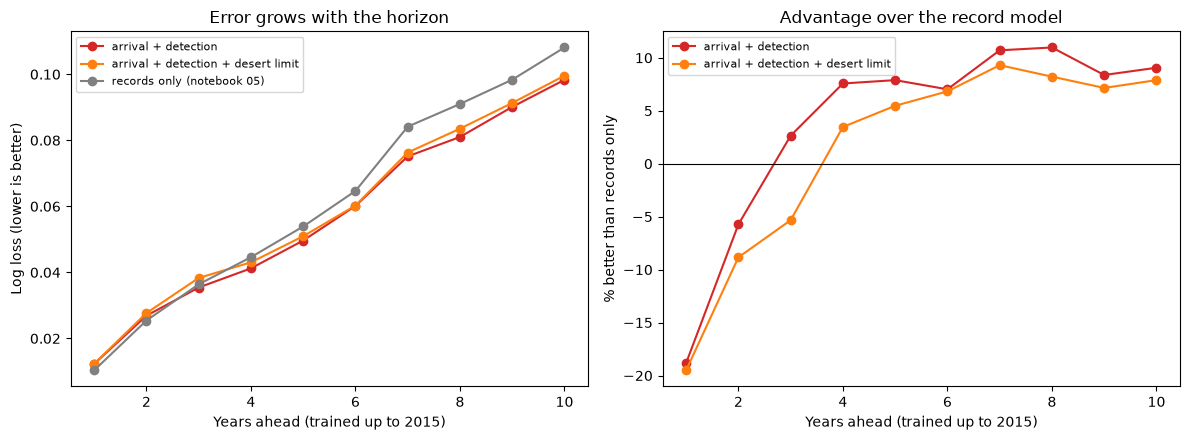

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colours = {REFERENCE: "grey", MODELS[1]: "tab:red", MODELS[2]: "tab:orange"}
subset = horizon.loc[horizon["trained up to"] == 2015]
for label, group in subset.groupby("model"):
    axes[0].plot(group["horizon (years)"], group["log loss"], "o-", color=colours[label], label=label)
    if label != REFERENCE:
        axes[1].plot(group["horizon (years)"], 100 * group["log loss skill vs records only"], "o-", color=colours[label], label=label)
axes[0].set(xlabel="Years ahead (trained up to 2015)", ylabel="Log loss (lower is better)", title="Error grows with the horizon")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(xlabel="Years ahead (trained up to 2015)", ylabel="% better than records only", title="Advantage over the record model")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "07_skill_by_horizon.png", dpi=150)

How to read it: the log loss grows with the horizon partly because more cells get colonised (more chances to be wrong), so the absolute value is not comparable across years. The skill against the record model, computed on the same cells and years, is the fair comparison.

## 3. Is the difference real? Paired spatial block bootstrap

In [10]:
block_codes = blocks.to_numpy()


def paired_difference(cutoff: int, model_a: str, model_b: str, n: int = 2000, seed: int = 0):
    '''Mean log loss of A minus B on the same cells in 2025, with a 95% interval from resampling 250-km blocks.'''
    new = first_year > cutoff
    y = (first_year <= 2025)[new].astype(float)
    loss_a, _ = cell_scores((runs[(cutoff, model_a)] <= 2025).mean(axis=0)[new], y)
    loss_b, _ = cell_scores((runs[(cutoff, model_b)] <= 2025).mean(axis=0)[new], y)
    difference = loss_a - loss_b
    codes, index = np.unique(block_codes[new], return_inverse=True)
    sums, counts = np.bincount(index, weights=difference), np.bincount(index)
    rng = np.random.default_rng(seed)
    draws = rng.integers(0, len(codes), size=(n, len(codes)))
    resampled = sums[draws].sum(axis=1) / counts[draws].sum(axis=1)
    low, high = np.percentile(resampled, [2.5, 97.5])
    return {"difference (A − B)": difference.mean(), "95% interval": f"{low:.4f} to {high:.4f}",
            "A better?": "yes" if high < 0 else ("no, B better" if low > 0 else "not distinguishable")}


comparisons = {}
for cutoff in CUTOFFS:
    comparisons[(cutoff, "A = arrival + detection, B = records only")] = paired_difference(cutoff, MODELS[1], REFERENCE)
    comparisons[(cutoff, "A = with desert limit, B = without")] = paired_difference(cutoff, MODELS[2], MODELS[1])
pd.DataFrame(comparisons).T

difference (A − B)  \
2015 A = arrival + detection, B = records only          -0.009796   
     A = with desert limit, B = without                  0.001264   
2020 A = arrival + detection, B = records only          -0.009643   
     A = with desert limit, B = without                 -0.001795   

                                                      95% interval  \
2015 A = arrival + detection, B = records only  -0.0208 to -0.0008   
     A = with desert limit, B = without          -0.0010 to 0.0037   
2020 A = arrival + detection, B = records only  -0.0167 to -0.0037   
     A = with desert limit, B = without          -0.0055 to 0.0019   

                                                          A better?  
2015 A = arrival + detection, B = records only                  yes  
     A = with desert limit, B = without         not distinguishable  
2020 A = arrival + detection, B = records only                  yes  
     A = with desert limit, B = without         not distinguishable

Negative differences mean model A has the lower (better) log loss. If the whole interval is below zero, the advantage holds across the map and is not driven by a few blocks; if the interval contains zero, the two models cannot be told apart with these data.

## 4. False positives and false negatives at a 50% threshold

In [11]:
rows = []
for (cutoff, label), records in runs.items():
    new = first_year > cutoff
    y = (first_year <= 2025)[new]
    predicted = (records <= 2025).mean(axis=0)[new] >= 0.5
    tp, fp = int((predicted & y).sum()), int((predicted & ~y).sum())
    fn, tn = int((~predicted & y).sum()), int((~predicted & ~y).sum())
    rows.append({"trained up to": cutoff, "model": label, "true positives": tp, "false positives": fp,
                 "false negatives": fn, "true negatives": tn,
                 "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1)})
pd.DataFrame(rows).set_index(["trained up to", "model"]).round(2)

true positives  \
trained up to model                                                
2015          records only (notebook 05)                       0   
              arrival + detection                             11   
              arrival + detection + desert limit              11   
2020          records only (notebook 05)                       0   
              arrival + detection                              3   
              arrival + detection + desert limit               2   

                                                  false positives  \
trained up to model                                                 
2015          records only (notebook 05)                        3   
              arrival + detection                              23   
              arrival + detection + desert limit               20   
2020          records only (notebook 05)                        0   
              arrival + detection                               3   
              arrival + detection + desert limit                1   

                                                  false negatives  \
trained up to model                                                 
2015          records only (notebook 05)                      313   
              arrival + detection                             302   
              arrival + detection + desert limit              302   
2020          records only (notebook 05)                      187   
              arrival + detection                             184   
              arrival + detection + desert limit              185   

                                                  true negatives  precision  \
trained up to model                                                           
2015          records only (notebook 05)                   11020       0.00   
              arrival + detection                          11000       0.32   
              arrival + detection + desert limit           11003       0.35   
2020          records only (notebook 05)                   11023       0.00   
              arrival + detection                          11020       0.50   
              arrival + detection + desert limit           11022       0.67   

                                                  recall  
trained up to model                                       
2015          records only (notebook 05)            0.00  
              arrival + detection                   0.04  
              arrival + detection + desert limit    0.04  
2020          records only (notebook 05)            0.00  
              arrival + detection                   0.02  
              arrival + detection + desert limit    0.01

**Reading it.** A false positive here is a cell forecast to get a toad record that did not get one by 2025; a false negative is a cell that got a record although the model gave it less than 50%. The model is built to give probabilities, so a single threshold throws information away: most new records happen in cells with probabilities between 5% and 50%, which a yes/no map at 50% counts as misses. That is why the main evaluation uses log loss and calibration, which judge every probability. A false positive for records may also be a true presence that nobody recorded yet, so for presence the "false positives" are partly unknowable.

## Takeaways

- **The improvement over the record model is real.** In both backtests the 95% interval of the paired block bootstrap for the difference in log loss is entirely below zero (−0.021 to −0.001 trained up to 2015; −0.017 to −0.004 trained up to 2020).
- **It depends on the horizon.** One and two years ahead, the record model is slightly better (−19% and −6% skill): the arrival + detection model spreads probability over cells where toads may already be unrecorded, and in the short term those cells rarely get a record. From three years on, the arrival + detection model is 3–11% better.
- **Ten years is the longest horizon tested**, so the forecast stops at 2035; going further would extrapolate beyond any validation.
- **The desert limit makes no detectable difference** (intervals include zero in both backtests), so the page shows only the main model and the limit is reported as a sensitivity check.
- **A 50% threshold is the wrong lens:** almost every cell that got its first record had been given less than 50% (recall 2–4%). First records are rare and spread over many cells with modest probabilities; log loss and calibration judge those probabilities directly.
- The 2015 model estimated more unrecorded presence in 2025 (about 440,000 km²) than the model retrained up to 2025 (about 350,000 km²): with ten more years of records, part of what looked hidden was recorded or ruled out.